## 라이브러리

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import MachineLearningLib as MLL
import pandas as pd

## 사용자 정의 함수

In [2]:
def euc_distance(x,y):
    dim = x.shape[0]
    dist_val = 0
    for i in range(dim):
        dist_val = dist_val + np.abs(x[i]-y[i])**2
    
    dist_val = np.sqrt(dist_val)# square root
    return dist_val;

## 사용자 정의 파라미터(user defined parameters)

In [3]:
k = 3
m0 = np.array([2,3])
m1 = np.array([5,4])
m2 = np.array([5,4])

## 입력

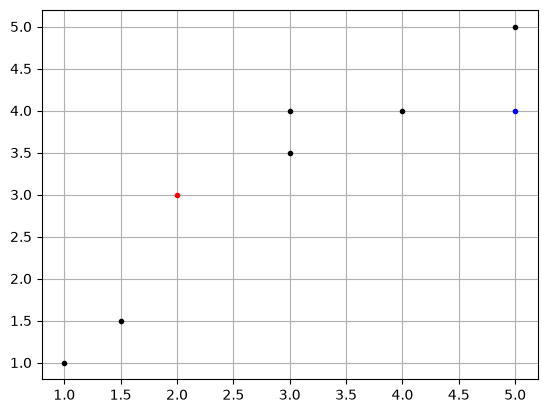

In [4]:
X = np.array([[1,1],
              [1.5,1.5],
              [5,5],
              [3,4],
              [4,4],
              [3,3.5]])
num, dim = X.shape

plt.plot(X[:,0], X[:,1], 'k.')
plt.plot(m0[0], m0[1], 'r.')
plt.plot(m1[0], m1[1], 'b.')
plt.grid()
plt.show()
# print(X)
# print(num,dim)

### iter1

In [5]:
for iters in range(100): # 최대 반복 횟수
    assign_mat = np.zeros(num)
    for i in range(0,num):
        dist1 = MLL.euc_distance(X[i,:],m0)
        dist2 = MLL.euc_distance(X[i,:],m1)
        dist3 = MLL.euc_distance(X[i,:],m2)
        if dist1 < dist2:
            assign_mat[i] = 0
        else:
            assign_mat[i] = 1
    
    new_m0 = X[assign_mat == 0,:].mean(axis=0)
    new_m1 = X[assign_mat == 1,:].mean(axis=0)
    print(iters, m0,m1,new_m0,new_m1)
    if (MLL.euc_distance(m0,new_m0) == 0) and (MLL.euc_distance(m1,new_m1) == 0):
        print("terminated")
        break
    else:
        m0 = new_m0
        m1 = new_m1

0 [2 3] [5 4] [2.125 2.5  ] [4.5 4.5]
1 [2.125 2.5  ] [4.5 4.5] [1.83333333 2.        ] [4.         4.33333333]
2 [1.83333333 2.        ] [4.         4.33333333] [1.25 1.25] [3.75  4.125]
3 [1.25 1.25] [3.75  4.125] [1.25 1.25] [3.75  4.125]
terminated


### Generalization

In [6]:
k = 3

colors = ['r','g','b','k','m','y','w']

In [16]:
# X = np.array([[1,1],
#               [1.5,1.5],
#               [5,5],
#               [3,4],
#               [4,4],
#               [3,3.5]])
# X = np.random.randint(0,100,[1000,2])
# num, dim = X.shape

df = pd.read_csv("datasets/iris.data", header=None)
df = df.to_numpy()
X = df[:,0:-1]
Y = df[:,-1]
num, dim = X.shape
print(num, dim)

# plt.plot(X[:,0], X[:,1], 'k.')
# plt.grid()
# plt.show()

M = X[np.random.randint(0,num,[k]),:]
print(M)

150 4
[[5.1 3.3 1.7 0.5]
 [5.2 3.5 1.5 0.2]
 [6.3 2.9 5.6 1.8]]


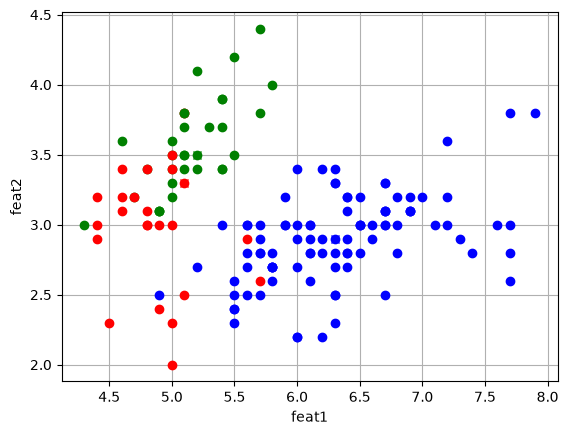

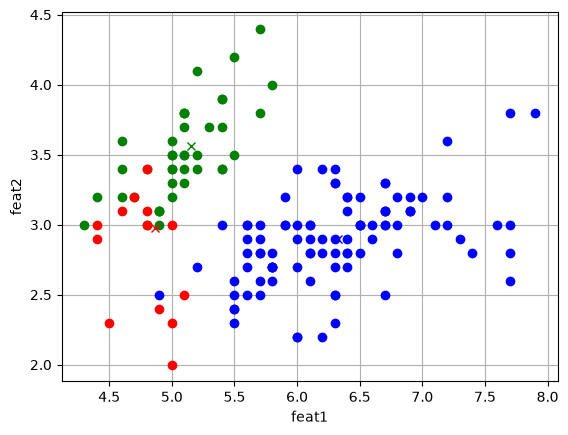

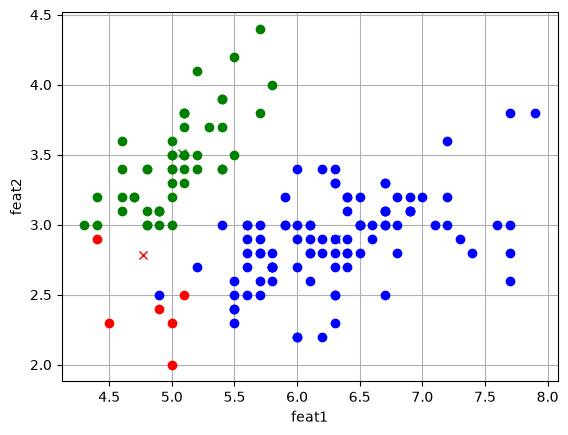

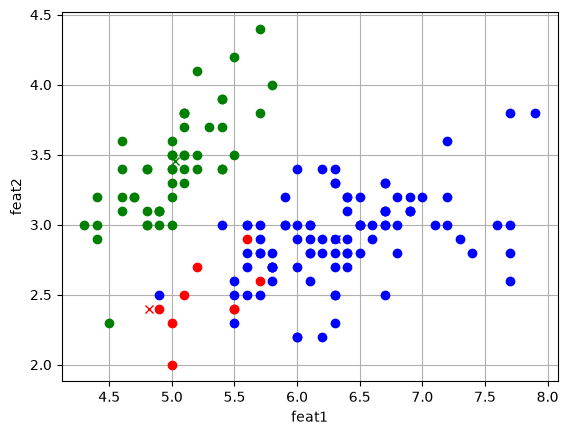

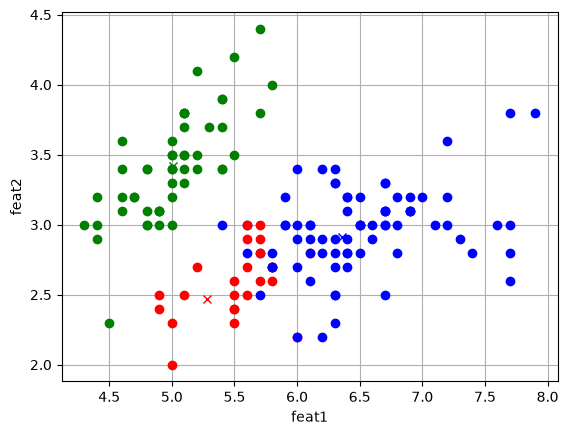

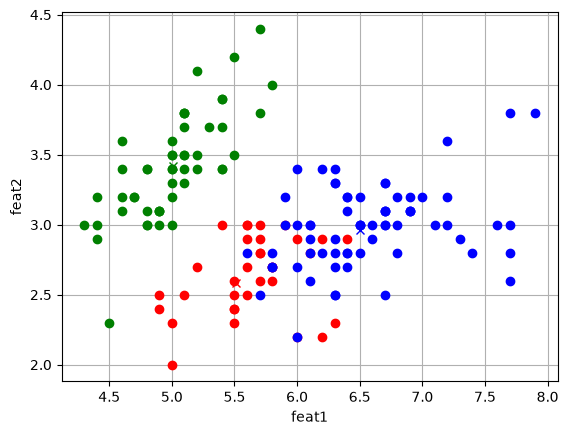

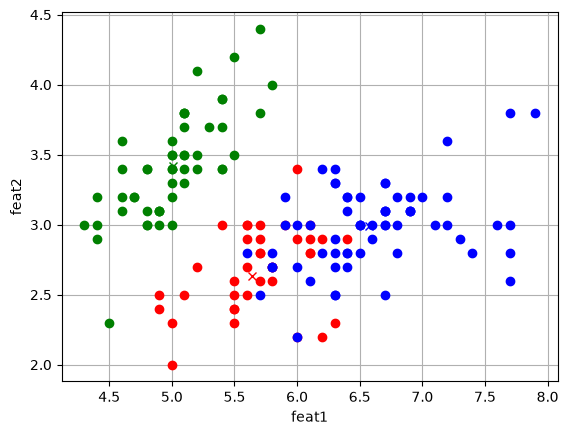

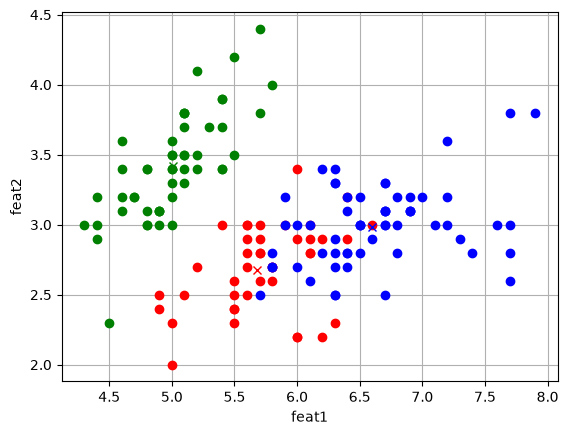

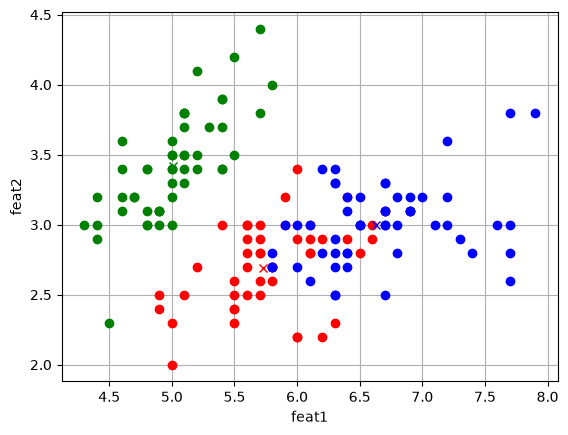

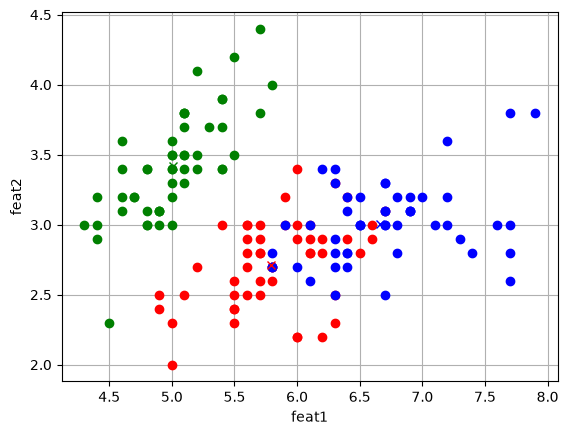

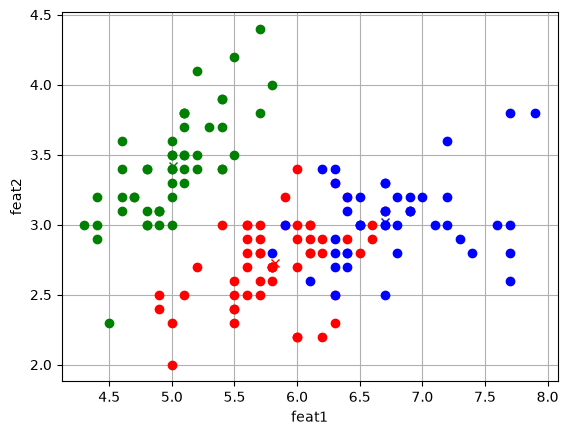

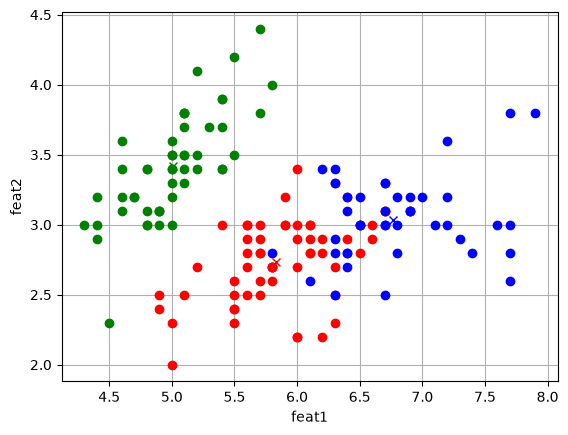

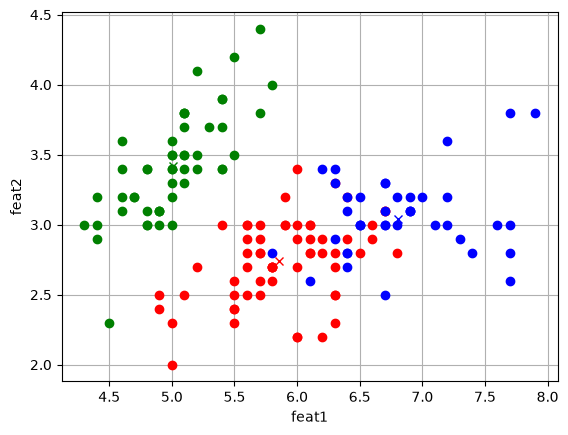

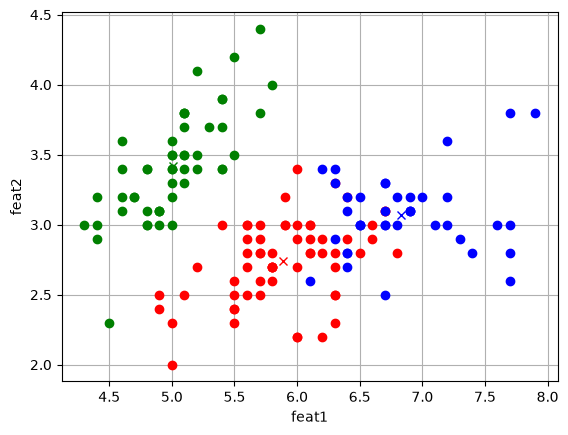

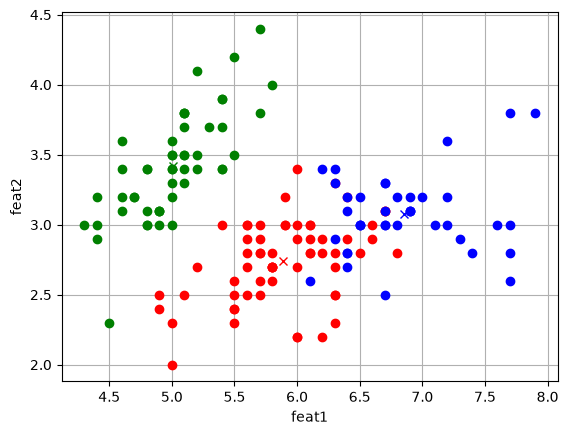

terminated


In [17]:
for iters in range(100): # 최대 반복 횟수
    assign_mat = np.zeros(num)
    for i in range(0,num):
        dist = np.zeros(k)
        for j in range(k):
            dist[j] = MLL.euc_distance(X[i,:],M[j,:])
        assign_mat[i] = np.argmin(dist)

    for i in range(0,num):
        plt.plot(X[i,0],X[i,1],marker="o",color=colors[int(assign_mat[i])])
    
    for i in range(k):
        plt.plot(M[i,0],M[i,1],marker="x",color=colors[i])
    plt.xlabel("feat1")
    plt.ylabel("feat2")
    plt.grid()
    plt.show()
        
    new_M = np.zeros((k,dim))
    for j in range(k):
        new_M[j,:] = X[assign_mat == j,:].mean(axis=0)
        
    # print(iters, M, new_M)
    if (MLL.euc_distance(M.flatten(),new_M.flatten()) == 0):
        print("terminated")
        break
    else:
        M = new_M

In [62]:
assign_mat

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 2.,
       2., 0., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 0., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 0., 2.,
       0., 0., 0., 0., 2., 0., 0., 0., 0., 0., 0., 2., 2., 0., 0., 0., 0.,
       2., 0., 2., 0., 2., 0., 0., 2., 2., 0., 0., 0., 0., 0., 2., 0., 0.,
       0., 0., 2., 0., 0., 0., 2., 0., 0., 0., 2., 0., 0., 2.])